In [66]:
import pandas as pd
import numpy as np

## Load the Data

In [67]:
df = pd.read_stata("df_analysis.dta")

In [68]:
df.shape

(2318008, 80)

In [69]:
print(df.columns.tolist())

['year', 'serial', 'month', 'hwtfinl', 'cpsid', 'asecflag', 'hflag', 'asecwth', 'statefip', 'county', 'metfips', 'hhincome', 'foodstmp', 'pernum', 'wtfinl', 'cpsidp', 'cpsidv', 'asecwt', 'earnweek2', 'age', 'sex', 'race', 'marst', 'vetstat', 'famsize', 'nchild', 'nchlt5', 'citizen', 'nativity', 'hispan', 'empstat', 'labforce', 'occ', 'classwkr', 'educ', 'diffany', 'occly', 'indly', 'classwly', 'fullpart', 'firmsize', 'ftotval', 'inctot', 'incwage', 'incbus', 'foodstamp', 'schllunch', 'disabwrk', 'health', 'emcontrb', 'himcaidly', 'himcaidnw', 'covergh', 'coverpi', 'phinsur', 'caidly', 'caidnw', 'caidpart', 'state_name', 'ur', '_merge', 'Educ', 'HSorless', 'college', 'female', 'white', 'black', 'hispanic', 'otherrace', 'SNAP1', 'married', 'parent', 'disable', 'famsize_cap', 'fpl_line', 'fpl_ratio', 'medicaid_eligible', 'sample1', 'medicaid', 'medic']


### Selecting variables

In [70]:
created_vars = [
    "Educ", "HSorless", "college",
    "female", "white", "black",
    "hispanic", "otherrace",
    "SNAP1", "married", "parent",
    "disable", "famsize_cap",
    "fpl_line", "fpl_ratio",
    "medicaid_eligible", "sample1",
    "medicaid", "medic"
]

In [71]:

df_clean = df.drop(columns=created_vars).copy()


print(df_clean.shape)

(2318008, 61)


### Examing Medicaid variables

In [72]:
medicaid_vars = [
    "himcaidly",
    "himcaidnw",
    "caidly",
    "caidnw",
    "caidpart"
]

for var in medicaid_vars:
    print(f"\n{var}")
    print(df_clean[var].value_counts(dropna=False))


himcaidly
himcaidly
1    1915751
2     401645
9        612
Name: count, dtype: int64

himcaidnw
himcaidnw
NaN    2011377
1.0     253648
2.0      52983
Name: count, dtype: int64

caidly
caidly
1    1958273
2     359123
9        612
Name: count, dtype: int64

caidnw
caidnw
NaN    2011377
1.0     257234
2.0      49397
Name: count, dtype: int64

caidpart
caidpart
NaN     2011377
99.0     251759
2.0       49856
1.0        5016
Name: count, dtype: int64


In [73]:
# Medicaid variables by year
for var in ["himcaidly", "caidly", "himcaidnw", "caidnw"]:
    print(f"\n{var}")
    print(pd.crosstab(
        df_clean["year"],
        df_clean[var],
        dropna=False
    ))


himcaidly
himcaidly       1      2    9
year                         
2008       176932  28756    0
2009       163850  26686    0
2010       162190  30420    0
2011       157930  29962    0
2012       153943  30319    0
2013       154521  30910    0
2014       149742  32740    0
2015       145290  35972    0
2016       134427  34415    0
2017       134609  34228    0
2018       131170  32365    0
2019       133198  30066  334
2020       117949  24806  278

caidly
caidly       1      2    9
year                      
2008    180862  24826    0
2009    167884  22652    0
2010    166728  25882    0
2011    162007  25885    0
2012    157786  26476    0
2013    158614  26817    0
2014    153548  28934    0
2015    148558  32704    0
2016    136869  31973    0
2017    137012  31825    0
2018    133628  29907    0
2019    135253  28011  334
2020    119524  23231  278

himcaidnw
himcaidnw     1.0    2.0     NaN
year                            
2008            0      0  205688
2009            

In [74]:
print(df_clean["year"].value_counts().sort_index())

year
2008    205688
2009    190536
2010    192610
2011    187892
2012    184262
2013    185431
2014    182482
2015    181262
2016    168842
2017    168837
2018    163535
2019    163598
2020    143033
Name: count, dtype: int64


In [75]:
income_vars = ["age", "famsize", "ftotval", "inctot"]

df_clean[income_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
age,2318008.0,3.381567e+01,2.161781e+01,0.0,15.0,33.0,50.00,85.0
famsize,2318008.0,3.524454e+00,1.703241e+00,1.0,2.0,3.0,5.00,16.0
ftotval,2318008.0,8.490146e+04,9.472364e+04,-19998.0,30935.0,62176.5,109003.00,2742997.0
inctot,2318008.0,2.489179e+08,4.323525e+08,-19998.0,13000.0,40000.0,578401.75,999999999.0


In [76]:
df_clean[income_vars].isna().sum()

age        0
famsize    0
ftotval    0
inctot     0
dtype: int64

In [77]:
df_clean["famsize"].value_counts().sort_index()

famsize
1.0     241757
2.0     486452
3.0     437084
4.0     569822
5.0     330248
6.0     147291
7.0      58271
8.0      24495
9.0      11554
10.0      5416
11.0      2741
12.0      1319
13.0       716
14.0       484
15.0       268
16.0        90
Name: count, dtype: int64

### Examine income data

In [78]:

print("Individual income:")
print(df_clean["inctot"].value_counts().head(15))

print("\nIndividual income above $1 million:")
print((df_clean["inctot"] > 1_000_000).sum())

print("\nIndividual income equal to 999999999:")
print((df_clean["inctot"] == 999999999).sum())

Individual income:
inctot
999999999    576926
0            231159
30000         22904
20000         21083
25000         18046
40000         16870
15000         14758
35000         14747
50000         13937
12000         12635
10000         12299
45000          9926
18000          9857
60000          9561
24000          8817
Name: count, dtype: int64

Individual income above $1 million:
578156

Individual income equal to 999999999:
576926


In [79]:
# Examine extreme values in family income

print("Family income:")
print(df_clean["ftotval"].value_counts().head(15))

print("\nNegative family income:")
print((df_clean["ftotval"] < 0).sum())

print("\nFamily income above $1 million:")
print((df_clean["ftotval"] > 1_000_000).sum())

Family income:
ftotval
0        50870
30000    17096
40000    14289
20000    14138
25000    13805
50000    12789
35000    12001
60000    10820
15000     9725
45000     9126
12000     7793
24000     7689
18000     7095
70000     6817
10000     6752
Name: count, dtype: int64

Negative family income:
1181

Family income above $1 million:
4082


In [80]:
# Extreme individual income values by year

df_clean.loc[
    df_clean["inctot"] == 999999999,
    "year"
].value_counts().sort_index()

year
2008    49771
2009    49873
2010    50193
2011    48134
2012    46751
2013    46883
2014    45558
2015    45103
2016    41861
2017    41274
2018    39522
2019    38850
2020    33153
Name: count, dtype: int64

### Restricting age sample

In [81]:
# Restrict sample to adults aged 18–64
df_sample = df_clean[
    df_clean["age"].between(18, 64)
].copy()

# Check sample size
print("Original observations:", len(df_clean))
print("Observations aged 18–64:", len(df_sample))
print("Observations excluded:", len(df_clean) - len(df_sample))

Original observations: 2318008
Observations aged 18–64: 1402720
Observations excluded: 915288


In [82]:
print("Special individual income codes:",
      (df_sample["inctot"] == 999999999).sum())

print("Negative family income:",
      (df_sample["ftotval"] < 0).sum())

Special individual income codes: 0
Negative family income: 820


### Verifying states

In [83]:

print(
    df_sample["statefip"]
    .value_counts()
    .sort_index()
)

statefip
1      19366
2      16986
4      20608
5      17655
6     145545
8      25905
9      24551
10     18773
11     22259
12     59397
13     31647
15     23810
16     17869
17     43306
18     20836
19     21299
20     18037
21     17196
22     20453
23     17019
24     28462
25     24188
26     30378
27     26491
28     17407
29     19826
30     16310
31     18894
32     21264
33     23436
34     30027
35     18710
36     60667
37     29043
38     17234
39     33855
40     17845
41     19409
42     37850
44     17768
45     19098
46     17387
47     20416
48     86493
49     19446
50     16791
51     28755
53     25047
54     17552
55     22568
56     17586
Name: count, dtype: int64


### Create Reference Year

In [84]:
# CPS-ASEC income generally refers to the previous year
df_sample["income_year"] = df_sample["year"] - 1

# Verify the reference years
print(
    df_sample[["year", "income_year"]]
    .drop_duplicates()
    .sort_values("year")
)

         year  income_year
0        2008         2007
205688   2009         2008
396224   2010         2009
588837   2011         2010
776727   2012         2011
960989   2013         2012
1146419  2014         2013
1328902  2015         2014
1510163  2016         2015
1679005  2017         2016
1847843  2018         2017
2011378  2019         2018
2174975  2020         2019


In [85]:
df_sample["fpl_region"] = np.select(
    [
        df_sample["statefip"] == 2,
        df_sample["statefip"] == 15
    ],
    [
        "Alaska",
        "Hawaii"
    ],
    default="Contiguous"
)

print(df_sample["fpl_region"].value_counts())

fpl_region
Contiguous    1361924
Hawaii          23810
Alaska          16986
Name: count, dtype: int64


In [86]:
import pandas as pd

# Year, contiguous base, contiguous increment,
# Alaska base, Alaska increment,
# Hawaii base, Hawaii increment

fpl_data = [
    [2007, 10210, 3480, 12770, 4350, 11750, 4000],
    [2008, 10400, 3600, 13000, 4500, 11960, 4140],
    [2009, 10830, 3740, 13530, 4680, 12460, 4300],
    [2010, 10830, 3740, 13530, 4680, 12460, 4300],
    [2011, 10890, 3820, 13600, 4780, 12540, 4390],
    [2012, 11170, 3960, 13970, 4950, 12860, 4550],
    [2013, 11490, 4020, 14350, 5030, 13230, 4620],
    [2014, 11670, 4060, 14580, 5080, 13420, 4670],
    [2015, 11770, 4160, 14720, 5200, 13550, 4780],
    [2016, 11880, 4140, 14840, 5200, 13670, 4780],
    [2017, 12060, 4180, 15060, 5230, 13860, 4810],
    [2018, 12140, 4320, 15180, 5400, 13960, 4970],
    [2019, 12490, 4420, 15600, 5530, 14380, 5080]
]

columns = [
    "income_year",
    "contiguous_base", "contiguous_increment",
    "alaska_base", "alaska_increment",
    "hawaii_base", "hawaii_increment"
]

fpl_wide = pd.DataFrame(fpl_data, columns=columns)

print(fpl_wide)

    income_year  contiguous_base  contiguous_increment  alaska_base  \
0          2007            10210                  3480        12770   
1          2008            10400                  3600        13000   
2          2009            10830                  3740        13530   
3          2010            10830                  3740        13530   
4          2011            10890                  3820        13600   
5          2012            11170                  3960        13970   
6          2013            11490                  4020        14350   
7          2014            11670                  4060        14580   
8          2015            11770                  4160        14720   
9          2016            11880                  4140        14840   
10         2017            12060                  4180        15060   
11         2018            12140                  4320        15180   
12         2019            12490                  4420        15600   

    a

### Putting the FPL table into long format

In [87]:
# Convert wide FPL table to long format

fpl_long = pd.concat([
    fpl_wide[[
        "income_year",
        "contiguous_base",
        "contiguous_increment"
    ]].rename(columns={
        "contiguous_base": "fpl_base",
        "contiguous_increment": "fpl_increment"
    }).assign(fpl_region="Contiguous"),

    fpl_wide[[
        "income_year",
        "alaska_base",
        "alaska_increment"
    ]].rename(columns={
        "alaska_base": "fpl_base",
        "alaska_increment": "fpl_increment"
    }).assign(fpl_region="Alaska"),

    fpl_wide[[
        "income_year",
        "hawaii_base",
        "hawaii_increment"
    ]].rename(columns={
        "hawaii_base": "fpl_base",
        "hawaii_increment": "fpl_increment"
    }).assign(fpl_region="Hawaii")

], ignore_index=True)

print(fpl_long.shape)
print(fpl_long.head())

(39, 4)
   income_year  fpl_base  fpl_increment  fpl_region
0         2007     10210           3480  Contiguous
1         2008     10400           3600  Contiguous
2         2009     10830           3740  Contiguous
3         2010     10830           3740  Contiguous
4         2011     10890           3820  Contiguous


In [88]:
# Merge historical FPL guidelines into the CPS data

df_sample = df_sample.merge(
    fpl_long,
    on=["income_year", "fpl_region"],
    how="left",
    validate="many_to_one"
)

# Verify the merge
print("Observations:", len(df_sample))

print(
    df_sample[["fpl_base", "fpl_increment"]]
    .isna()
    .sum()
)

Observations: 1402720
fpl_base         0
fpl_increment    0
dtype: int64


In [89]:
# Calculate the poverty guideline for each observation
df_sample["fpl_line"] = (
    df_sample["fpl_base"]
    + (df_sample["famsize"] - 1) * df_sample["fpl_increment"]
)

# Calculate family income relative to FPL
df_sample["fpl_ratio"] = (
    df_sample["ftotval"] / df_sample["fpl_line"]
)

# Examine the results
print(
    df_sample[["fpl_line", "fpl_ratio"]]
    .describe()
)

           fpl_line     fpl_ratio
count  1.402720e+06  1.402720e+06
mean   2.036768e+04  4.454450e+00
std    6.652536e+03  4.795932e+00
min    1.021000e+04 -1.836364e+00
25%    1.551000e+04  1.791402e+00
50%    1.992000e+04  3.390992e+00
75%    2.430000e+04  5.645241e+00
max    8.822000e+04  1.812952e+02


In [90]:
# Number of observations at or below 138% FPL
print(
    "At or below 138% FPL:",
    (df_sample["fpl_ratio"] <= 1.38).sum()
)

# Number above 138% FPL
print(
    "Above 138% FPL:",
    (df_sample["fpl_ratio"] > 1.38).sum()
)

# Check negative FPL ratios
print(
    "Negative FPL ratios:",
    (df_sample["fpl_ratio"] < 0).sum()
)

# Check missing FPL ratios
print(
    "Missing FPL ratios:",
    df_sample["fpl_ratio"].isna().sum()
)

At or below 138% FPL: 256722
Above 138% FPL: 1145998
Negative FPL ratios: 820
Missing FPL ratios: 0


### Restrict to adults at or below 138% FPL(Medicaid-eligible)

In [91]:
# Create provisional low-income sample
df_lowincome = df_sample[
    df_sample["fpl_ratio"] <= 1.38
].copy()

# Check sample size
print("Low-income sample:", len(df_lowincome))

# Check FPL distribution
print(df_lowincome["fpl_ratio"].describe())

Low-income sample: 256722
count    256722.000000
mean          0.713005
std           0.440456
min          -1.836364
25%           0.358102
50%           0.775681
75%           1.091270
max           1.380000
Name: fpl_ratio, dtype: float64


### Constructing Medicaid

In [92]:
# Construct binary Medicaid outcome
df_lowincome["medicaid"] = df_lowincome["himcaidly"].map({
    1: 0,
    2: 1
})

# Examine enrollment distribution
print(
    df_lowincome["medicaid"]
    .value_counts(dropna=False)
)

# Examine enrollment percentages
print(
    df_lowincome["medicaid"]
    .value_counts(normalize=True, dropna=True) * 100
)

medicaid
0    178566
1     78156
Name: count, dtype: int64
medicaid
0    69.556174
1    30.443826
Name: proportion, dtype: float64


### Check missing values

In [93]:
# Candidate predictors
candidate_vars = [
    "year",
    "statefip",
    "age",
    "sex",
    "race",
    "hispan",
    "marst",
    "educ",
    "citizen",
    "nativity",
    "empstat",
    "famsize",
    "nchild",
    "ftotval",
    "inctot",
    "health",
    "diffany"
]

# Examine missing values
missing_summary = df_lowincome[candidate_vars].isna().sum()

print(missing_summary)

year            0
statefip        0
age             0
sex             0
race            0
hispan          0
marst           0
educ            0
citizen         0
nativity        0
empstat         0
famsize         0
nchild          0
ftotval         0
inctot          0
health          0
diffany     21929
dtype: int64


### Checking diffany (disability)

In [94]:
# Examine missing disability information by year

missing_diffany = (
    df_lowincome.groupby("year")["diffany"]
    .agg(
        total="size",
        missing=lambda x: x.isna().sum()
    )
)

missing_diffany["missing_pct"] = (
    missing_diffany["missing"]
    / missing_diffany["total"] * 100
)

print(missing_diffany)

      total  missing  missing_pct
year                             
2008  21929    21929        100.0
2009  19636        0          0.0
2010  23696        0          0.0
2011  23321        0          0.0
2012  22582        0          0.0
2013  21631        0          0.0
2014  20843        0          0.0
2015  20698        0          0.0
2016  18109        0          0.0
2017  18295        0          0.0
2018  17243        0          0.0
2019  16094        0          0.0
2020  12645        0          0.0


In [95]:
# Examine disability variable categories

print(
    df_lowincome["diffany"]
    .value_counts(dropna=False)
    .sort_index()
)

diffany
1.0    234793
NaN     21929
Name: count, dtype: int64


### Examine other features

In [96]:
categorical_vars = [
    "sex",
    "race",
    "hispan",
    "marst",
    "educ",
    "citizen",
    "nativity",
    "empstat",
    "health",
    "disabwrk"
]

for var in categorical_vars:
    print(f"\n--- {var} ---")
    print(
        df_lowincome[var]
        .value_counts(dropna=False)
        .sort_index()
    )


--- sex ---
sex
1    106278
2    150444
Name: count, dtype: int64

--- race ---
race
100    181907
200     46141
300      6761
651     14020
652      2092
801      1495
802      2162
803       632
804       255
805       322
806        55
807        23
808        17
809       306
810       197
811        14
812        26
813       226
814         9
815         3
816         3
817         2
818         5
819         1
820        24
830        24
Name: count, dtype: int64

--- hispan ---
hispan
0      178512
100     52630
200      5944
300      1976
400      1266
500      1620
600      3263
610      7230
611      2672
612      1609
Name: count, dtype: int64

--- marst ---
marst
1     81576
2      6469
3     11812
4     33207
5      5764
6    117894
Name: count, dtype: int64

--- educ ---
educ
2       1659
10      3793
20      9312
30      7907
40      9609
50     10161
60     16242
71      8022
73     92992
81     50991
91      8216
92      9425
111    21617
123     5247
124      800
12

In [97]:
created_features = [
    "Educ",
    "HSorless",
    "college",
    "female",
    "white",
    "black",
    "hispanic",
    "otherrace",
    "married",
    "parent",
    "disable"
]

for var in created_features:
    print(f"\n--- {var} ---")
    print(df[var].value_counts(dropna=False).sort_index())


--- Educ ---
Educ
1.0    885454
2.0    466487
3.0    464174
4.0    501893
Name: count, dtype: int64

--- HSorless ---
HSorless
0     966067
1    1351941
Name: count, dtype: int64

--- college ---
college
0    1816115
1     501893
Name: count, dtype: int64

--- female ---
female
0    1126738
1    1191270
Name: count, dtype: int64

--- white ---
white
0     915084
1    1402924
Name: count, dtype: int64

--- black ---
black
0    2063056
1     254952
Name: count, dtype: int64

--- hispanic ---
hispanic
0    1875813
1     442195
Name: count, dtype: int64

--- otherrace ---
otherrace
0    2100071
1     217937
Name: count, dtype: int64

--- married ---
married
0.0    1381603
1.0     936405
Name: count, dtype: int64

--- parent ---
parent
0    1551663
1     766345
Name: count, dtype: int64

--- disable ---
disable
0    2318008
Name: count, dtype: int64


In [98]:
# Check whether previous race indicators overlap

race_vars = ["white", "black", "hispanic", "otherrace"]

df["race_total"] = df[race_vars].sum(axis=1)

print(df["race_total"].value_counts(dropna=False))

race_total
1    2318008
Name: count, dtype: int64


### Creating the features

In [99]:

# 1. Race and ethnicity
df_lowincome["race_group"] = np.select(
    [
        df_lowincome["hispan"] != 0,
        (df_lowincome["hispan"] == 0) & (df_lowincome["race"] == 100),
        (df_lowincome["hispan"] == 0) & (df_lowincome["race"] == 200)
    ],
    [
        "Hispanic",
        "Non-Hispanic White",
        "Non-Hispanic Black"
    ],
    default="Non-Hispanic Other"
)

# 2. Education
df_lowincome["education_group"] = np.select(
    [
        df_lowincome["educ"] < 73,
        df_lowincome["educ"] == 73,
        df_lowincome["educ"].isin([81, 91, 92]),
        df_lowincome["educ"] >= 111
    ],
    [
        "Less than high school",
        "High school",
        "Some college/Associate",
        "Bachelor's or higher"
    ],
    default="Unknown"
)

# 3. Marital status
df_lowincome["marital_group"] = np.select(
    [
        df_lowincome["marst"].isin([1, 2]),
        df_lowincome["marst"].isin([3, 4, 5]),
        df_lowincome["marst"] == 6
    ],
    [
        "Married",
        "Previously married",
        "Never married"
    ],
    default="Unknown"
)

# 4. Employment status
df_lowincome["employment_group"] = np.select(
    [
        df_lowincome["empstat"].isin([10, 12]),
        df_lowincome["empstat"].isin([21, 22]),
        df_lowincome["empstat"].isin([32, 34, 36])
    ],
    [
        "Employed",
        "Unemployed",
        "Not in labor force"
    ],
    default="Unknown"
)

# 5. Citizenship
df_lowincome["citizenship_group"] = np.select(
    [
        df_lowincome["citizen"].isin([1, 2, 3]),
        df_lowincome["citizen"] == 4,
        df_lowincome["citizen"] == 5
    ],
    [
        "Native-born citizen",
        "Naturalized citizen",
        "Noncitizen"
    ],
    default="Unknown"
)

# 6. Sex
df_lowincome["sex_group"] = df_lowincome["sex"].map({
    1: "Male",
    2: "Female"
})

# 7. Self-reported health
df_lowincome["health_group"] = df_lowincome["health"].map({
    1: "Excellent",
    2: "Very good",
    3: "Good",
    4: "Fair",
    5: "Poor"
})

# 8. Number of children
df_lowincome["parent_group"] = np.select(
    [
        df_lowincome["nchild"] == 0,
        df_lowincome["nchild"] == 1,
        df_lowincome["nchild"] >= 2
    ],
    [
        "No children",
        "One child",
        "Two or more children"
    ],
    default="Unknown"
)


In [100]:

categorical_features = [
    "race_group",
    "education_group",
    "marital_group",
    "employment_group",
    "citizenship_group",
    "sex_group",
    "health_group",
    "parent_group"
]

for var in categorical_features:
    print(f"\n--- {var} ---")
    print(df_lowincome[var].value_counts(dropna=False))



--- race_group ---
race_group
Non-Hispanic White    109733
Hispanic               78210
Non-Hispanic Black     43576
Non-Hispanic Other     25203
Name: count, dtype: int64

--- education_group ---
education_group
High school               92992
Some college/Associate    68632
Less than high school     66705
Bachelor's or higher      28393
Name: count, dtype: int64

--- marital_group ---
marital_group
Never married         117894
Married                88045
Previously married     50783
Name: count, dtype: int64

--- employment_group ---
employment_group
Employed              127405
Not in labor force    104024
Unemployed             25293
Name: count, dtype: int64

--- citizenship_group ---
citizenship_group
Native-born citizen    188550
Noncitizen              50652
Naturalized citizen     17520
Name: count, dtype: int64

--- sex_group ---
sex_group
Female    150444
Male      106278
Name: count, dtype: int64

--- health_group ---
health_group
Good         80479
Very good    76452
Exc

### Fetures and summary stats

In [101]:
numerical_features = [
    "age",
    "famsize",
    "nchild",
    "ftotval",
    "inctot",
    "fpl_ratio"
]

# Summary statistics
print(
    df_lowincome[numerical_features]
    .describe()
    .T
)

# Missing values
print(
    df_lowincome[numerical_features]
    .isna()
    .sum()
)

              count          mean           std           min          25%  \
age        256722.0     36.436133     12.877812     18.000000    25.000000   
famsize    256722.0      3.483402      1.985859      1.000000     2.000000   
nchild     256722.0      1.235960      1.433757      0.000000     0.000000   
ftotval    256722.0  15400.598394  11449.588989 -19998.000000  6660.000000   
inctot     256722.0   9248.914086   9433.561062 -19998.000000     0.000000   
fpl_ratio  256722.0      0.713005      0.440456     -1.836364     0.358102   

                    50%          75%       max  
age           34.000000     46.00000     64.00  
famsize        3.000000      5.00000     16.00  
nchild         1.000000      2.00000      9.00  
ftotval    14500.000000  22880.00000  89308.00  
inctot      7700.000000  15000.00000  78000.00  
fpl_ratio      0.775681      1.09127      1.38  
age          0
famsize      0
nchild       0
ftotval      0
inctot       0
fpl_ratio    0
dtype: int64


In [102]:
# Examine negative income observations

print(
    "Negative family income:",
    (df_lowincome["ftotval"] < 0).sum()
)

print(
    "Negative individual income:",
    (df_lowincome["inctot"] < 0).sum()
)

print(
    "Both family and individual income negative:",
    (
        (df_lowincome["ftotval"] < 0) &
        (df_lowincome["inctot"] < 0)
    ).sum()
)

Negative family income: 820
Negative individual income: 1022
Both family and individual income negative: 598


### Checking the IDs

In [103]:
# Examine repeated individual identifiers

print("Total observations:", len(df_lowincome))

print(
    "Unique CPS individual IDs:",
    df_lowincome["cpsidp"].nunique()
)

print(
    "Repeated individual IDs:",
    df_lowincome["cpsidp"].duplicated().sum()
)

# Examine missing and zero identifiers
print(
    "Missing CPS IDs:",
    df_lowincome["cpsidp"].isna().sum()
)

print(
    "Zero CPS IDs:",
    (df_lowincome["cpsidp"] == 0).sum()
)

Total observations: 256722
Unique CPS individual IDs: 220245
Repeated individual IDs: 36477
Missing CPS IDs: 0
Zero CPS IDs: 0


In [104]:
# Count observations per individual
id_counts = df_lowincome["cpsidp"].value_counts()

# Distribution of observation counts
print(
    id_counts.value_counts().sort_index()
)

# Maximum observations per individual
print(
    "Maximum observations per individual:",
    id_counts.max()
)

count
1    183768
2     36477
Name: count, dtype: int64
Maximum observations per individual: 2


In [105]:
# Count distinct survey years per individual
years_per_person = (
    df_lowincome.groupby("cpsidp")["year"]
    .nunique()
)

print(
    years_per_person.value_counts().sort_index()
)

year
1    183768
2     36477
Name: count, dtype: int64


### Exploring Household identifiers

In [106]:

# Check available household identifiers
household_vars = ["cpsid", "serial", "year"]

print(df_lowincome[household_vars].isna().sum())

# Number of unique CPS household IDs
print(
    "Unique CPS household IDs:",
    df_lowincome["cpsid"].nunique()
)

# Number of unique survey-year household combinations
print(
    "Unique year-serial households:",
    df_lowincome[["year", "serial"]]
    .drop_duplicates()
    .shape[0]
)

# Individuals per CPS household ID
household_sizes = (
    df_lowincome.groupby("cpsid")["cpsidp"]
    .nunique()
)

print(
    "\nIndividuals per CPS household ID:"
)

print(
    household_sizes.value_counts()
    .sort_index()
    .head(15)
)


cpsid     0
serial    0
year      0
dtype: int64
Unique CPS household IDs: 139402
Unique year-serial households: 166820

Individuals per CPS household ID:
cpsidp
1     77970
2     47593
3      9801
4      2989
5       719
6       231
7        67
8        17
9        11
10        2
12        1
13        1
Name: count, dtype: int64


### Final Identifier Check

In [107]:
# Number of distinct household IDs associated with each individual
households_per_person = (
    df_lowincome.groupby("cpsidp")["cpsid"]
    .nunique()
)

print(
    households_per_person.value_counts().sort_index()
)

print(
    "Individuals associated with multiple household IDs:",
    (households_per_person > 1).sum()
)

cpsid
1    220245
Name: count, dtype: int64
Individuals associated with multiple household IDs: 0


### Train/ Test Split

In [108]:

from sklearn.model_selection import GroupShuffleSplit

# First split: 70% training, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.70,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(
        df_lowincome,
        groups=df_lowincome["cpsid"]
    )
)

df_train = df_lowincome.iloc[train_idx].copy()
df_temp = df_lowincome.iloc[temp_idx].copy()

# Second split: divide temporary data equally
# into validation and testing
split2 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    split2.split(
        df_temp,
        groups=df_temp["cpsid"]
    )
)

df_val = df_temp.iloc[val_idx].copy()
df_test = df_temp.iloc[test_idx].copy()

print("Training:", df_train.shape)
print("Validation:", df_val.shape)
print("Testing:", df_test.shape)


Training: (179792, 76)
Validation: (38434, 76)
Testing: (38496, 76)


### Verify Overlap

In [109]:

train_households = set(df_train["cpsid"])
val_households = set(df_val["cpsid"])
test_households = set(df_test["cpsid"])

print(
    "Train-Val overlap:",
    len(train_households & val_households)
)

print(
    "Train-Test overlap:",
    len(train_households & test_households)
)

print(
    "Val-Test overlap:",
    len(val_households & test_households)
)


Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [110]:

train_households = set(df_train["cpsid"])
val_households = set(df_val["cpsid"])
test_households = set(df_test["cpsid"])

print(
    "Train-Val overlap:",
    len(train_households & val_households)
)

print(
    "Train-Test overlap:",
    len(train_households & test_households)
)

print(
    "Val-Test overlap:",
    len(val_households & test_households)
)


Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


### Check Enrollment rates

In [111]:

for name, data in [
    ("Training", df_train),
    ("Validation", df_val),
    ("Testing", df_test)
]:
    print(
        name,
        "Observations:", len(data),
        "Medicaid enrollment rate:",
        round(data["medicaid"].mean() * 100, 2),
        "%"
    )


Training Observations: 179792 Medicaid enrollment rate: 30.41 %
Validation Observations: 38434 Medicaid enrollment rate: 30.6 %
Testing Observations: 38496 Medicaid enrollment rate: 30.43 %


### Creating features and the target

In [112]:

# Categorical predictors
categorical_features = [
    "race_group",
    "education_group",
    "marital_group",
    "employment_group",
    "citizenship_group",
    "sex_group",
    "health_group",
    "statefip"
]

# Numerical predictors
numerical_features = [
    "age",
    "famsize",
    "nchild",
    "fpl_ratio",
    "year"
]

# Combine predictors
features = categorical_features + numerical_features

# Create feature matrices
X_train = df_train[features].copy()
X_val = df_val[features].copy()
X_test = df_test[features].copy()

# Create target vectors
y_train = df_train["medicaid"].copy()
y_val = df_val["medicaid"].copy()
y_test = df_test["medicaid"].copy()

# Check dimensions
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\ny_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)


X_train: (179792, 13)
X_val: (38434, 13)
X_test: (38496, 13)

y_train: (179792,)
y_val: (38434,)
y_test: (38496,)


### Create our preprocessing pipeline

In [113]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# Fit only on training data
preprocessor.fit(X_train)

# Transform training and validation data
X_train_processed = preprocessor.transform(X_train)
X_val_processed = preprocessor.transform(X_val)

# Examine the resulting dimensions
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("Original validation shape:", X_val.shape)
print("Processed validation shape:", X_val_processed.shape)


Original training shape: (179792, 13)
Processed training shape: (179792, 80)
Original validation shape: (38434, 13)
Processed validation shape: (38434, 80)


In [114]:
preprocessor.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``

### Train Decision Tree

In [115]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# Initialize Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train model
dt_model.fit(X_train_processed, y_train)

# Predict Medicaid enrollment
y_train_pred = dt_model.predict(X_train_processed)
y_val_pred = dt_model.predict(X_val_processed)

# Predicted probabilities
y_train_prob = dt_model.predict_proba(X_train_processed)[:, 1]
y_val_prob = dt_model.predict_proba(X_val_processed)[:, 1]

# Evaluate performance
print("TRAINING PERFORMANCE")
print("Accuracy:", round(accuracy_score(y_train, y_train_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_train, y_train_prob), 4))

print("\nVALIDATION PERFORMANCE")
print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob), 4))


TRAINING PERFORMANCE
Accuracy: 0.6968
ROC-AUC: 0.6796

VALIDATION PERFORMANCE
Accuracy: 0.6951
ROC-AUC: 0.6761


### Varying depths

In [116]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
import pandas as pd

depths = [3, 5, 10, 15, 20]

results = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train_processed, y_train)

    train_prob = model.predict_proba(
        X_train_processed
    )[:, 1]

    val_prob = model.predict_proba(
        X_val_processed
    )[:, 1]

    results.append({
        "max_depth": depth,
        "train_auc": roc_auc_score(y_train, train_prob),
        "val_auc": roc_auc_score(y_val, val_prob)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))


   max_depth  train_auc  val_auc
0          3     0.6389   0.6408
1          5     0.6796   0.6761
2         10     0.7452   0.7131
3         15     0.8282   0.6934
4         20     0.9192   0.6422


### First Random Forest

In [117]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

# Predict probabilities
rf_train_prob = rf_model.predict_proba(
    X_train_processed
)[:, 1]

rf_val_prob = rf_model.predict_proba(
    X_val_processed
)[:, 1]

# Predict enrollment categories
rf_train_pred = rf_model.predict(X_train_processed)
rf_val_pred = rf_model.predict(X_val_processed)

# Evaluate performance
print("RANDOM FOREST - TRAINING")
print("Accuracy:", round(
    accuracy_score(y_train, rf_train_pred), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_train, rf_train_prob), 4
))

print("\nRANDOM FOREST - VALIDATION")
print("Accuracy:", round(
    accuracy_score(y_val, rf_val_pred), 4
))
print("ROC-AUC:", round(
    roc_auc_score(y_val, rf_val_prob), 4
))


RANDOM FOREST - TRAINING
Accuracy: 0.7196
ROC-AUC: 0.7653

RANDOM FOREST - VALIDATION
Accuracy: 0.7143
ROC-AUC: 0.7482


### Tune Random Forest Depth

In [118]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import pandas as pd

depths = [5, 10, 15, 20, None]

rf_results = []

for depth in depths:

    rf = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train_processed, y_train)

    train_prob = rf.predict_proba(
        X_train_processed
    )[:, 1]

    val_prob = rf.predict_proba(
        X_val_processed
    )[:, 1]

    rf_results.append({
        "max_depth": str(depth),
        "train_auc": roc_auc_score(y_train, train_prob),
        "val_auc": roc_auc_score(y_val, val_prob)
    })

rf_results_df = pd.DataFrame(rf_results)

print(rf_results_df.round(4))


  max_depth  train_auc  val_auc
0         5     0.7217   0.7176
1        10     0.7653   0.7482
2        15     0.8116   0.7645
3        20     0.8487   0.7706
4      None     0.8868   0.7735


### I try leaf depth = None

In [120]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import pandas as pd



    

In [121]:
leaf_sizes = [1, 5, 10, 20, 50]

leaf_results = []

for leaf in leaf_sizes:

    rf = RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1
    )

In [125]:
rf.fit(X_train_processed, y_train)

train_prob = rf.predict_proba(
        X_train_processed
    )[:, 1]

val_prob = rf.predict_proba(
        X_val_processed
    )[:, 1]

leaf_results.append({
        "min_samples_leaf": leaf,
        "train_auc": roc_auc_score(y_train, train_prob),
        "val_auc": roc_auc_score(y_val, val_prob)
    })

leaf_results_df = pd.DataFrame(leaf_results)

print(leaf_results_df.round(4))


   min_samples_leaf  train_auc  val_auc
0                50     0.7792   0.7587


### Investigating Feature Engineering

In [126]:

# Add income variables to the existing feature set
features_income = features + ["ftotval", "inctot"]

# Create new feature matrices
X_train_income = df_train[features_income].copy()
X_val_income = df_val[features_income].copy()

# Update numerical feature list
numerical_features_income = numerical_features + [
    "ftotval",
    "inctot"
]

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# Preprocessing
preprocessor_income = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features_income
        )
    ]
)

# Fit preprocessing on training data only
X_train_income_processed = (
    preprocessor_income.fit_transform(X_train_income)
)

X_val_income_processed = (
    preprocessor_income.transform(X_val_income)
)

# Train Random Forest with additional income predictors
rf_income = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_income.fit(X_train_income_processed, y_train)

# Predict validation probabilities
income_val_prob = rf_income.predict_proba(
    X_val_income_processed
)[:, 1]

# Compare ROC-AUC
income_auc = roc_auc_score(y_val, income_val_prob)

print("Original Random Forest ROC-AUC:", 0.7735)
print("Random Forest with income ROC-AUC:", round(income_auc, 4))


Original Random Forest ROC-AUC: 0.7735
Random Forest with income ROC-AUC: 0.7771


#### There was obniously an improvement in the performance after i added income. How do i decide which features to include? I will use permutation feature importance.

In [127]:

from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
import pandas as pd

# Combine preprocessing and trained Random Forest
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor_income),
    ("model", rf_income)
])

# Calculate permutation importance on validation data
perm_results = permutation_importance(
    rf_pipeline,
    X_val_income,
    y_val,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

# Create results table
importance_df = pd.DataFrame({
    "feature": X_val_income.columns,
    "importance_mean": perm_results.importances_mean,
    "importance_std": perm_results.importances_std
})

importance_df = importance_df.sort_values(
    "importance_mean",
    ascending=False
)

print(importance_df.round(4))


              feature  importance_mean  importance_std
3    employment_group           0.0525          0.0020
7            statefip           0.0494          0.0010
12               year           0.0373          0.0010
10             nchild           0.0296          0.0004
6        health_group           0.0189          0.0003
14             inctot           0.0182          0.0004
8                 age           0.0182          0.0007
5           sex_group           0.0160          0.0002
2       marital_group           0.0132          0.0007
4   citizenship_group           0.0117          0.0005
9             famsize           0.0109          0.0003
1     education_group           0.0105          0.0005
0          race_group           0.0081          0.0001
11          fpl_ratio           0.0049          0.0002
13            ftotval           0.0047          0.0004


### Comparing models without state and year

In [128]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# Remove state and year
features_no_state_year = [
    f for f in features_income
    if f not in ["statefip", "year"]
]

categorical_no_state_year = [
    f for f in categorical_features
    if f != "statefip"
]

numerical_no_state_year = [
    f for f in numerical_features_income
    if f != "year"
]

# Create preprocessing pipeline
preprocessor_no_state_year = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_no_state_year
        ),
        (
            "numerical",
            "passthrough",
            numerical_no_state_year
        )
    ]
)

# Create Random Forest pipeline
rf_no_state_year = Pipeline([
    ("preprocessor", preprocessor_no_state_year),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
rf_no_state_year.fit(
    df_train[features_no_state_year],
    y_train
)

# Predict validation probabilities
prob_no_state_year = rf_no_state_year.predict_proba(
    df_val[features_no_state_year]
)[:, 1]

# Evaluate
auc_no_state_year = roc_auc_score(
    y_val,
    prob_no_state_year
)

print("Full model ROC-AUC:", 0.7771)
print(
    "Without state and year ROC-AUC:",
    round(auc_no_state_year, 4)
)


Full model ROC-AUC: 0.7771
Without state and year ROC-AUC: 0.7218


In [129]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

def evaluate_feature_subset(excluded_features):

    selected_features = [
        f for f in features_income
        if f not in excluded_features
    ]

    selected_categorical = [
        f for f in categorical_features
        if f in selected_features
    ]

    selected_numerical = [
        f for f in numerical_features_income
        if f in selected_features
    ]

    preprocessor_subset = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                selected_categorical
            ),
            (
                "numerical",
                "passthrough",
                selected_numerical
            )
        ]
    )

    model = Pipeline([
        ("preprocessor", preprocessor_subset),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=None,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(
        df_train[selected_features],
        y_train
    )

    val_prob = model.predict_proba(
        df_val[selected_features]
    )[:, 1]

    return roc_auc_score(y_val, val_prob)


auc_no_state = evaluate_feature_subset(["statefip"])
auc_no_year = evaluate_feature_subset(["year"])

print("Full model:", 0.7771)
print("Without state:", round(auc_no_state, 4))
print("Without year:", round(auc_no_year, 4))
print("Without both:", 0.7218)


Full model: 0.7771
Without state: 0.7422
Without year: 0.7605
Without both: 0.7218


### Let us evaluate with  precision, recall, F1-score, balanced accuracy, and the confusion matrix.

In [130]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

# Predicted classes using the default 0.50 threshold
y_val_pred_income = (income_val_prob >= 0.50).astype(int)

# Classification metrics
print("CLASSIFICATION REPORT")
print(
    classification_report(
        y_val,
        y_val_pred_income,
        target_names=["Not Enrolled", "Enrolled"],
        digits=4
    )
)

# Confusion matrix
print("\nCONFUSION MATRIX")
print(
    confusion_matrix(
        y_val,
        y_val_pred_income
    )
)

# Balanced accuracy
print(
    "\nBalanced Accuracy:",
    round(
        balanced_accuracy_score(
            y_val,
            y_val_pred_income
        ),
        4
    )
)


CLASSIFICATION REPORT
              precision    recall  f1-score   support

Not Enrolled     0.7590    0.9310    0.8362     26674
    Enrolled     0.6779    0.3295    0.4435     11760

    accuracy                         0.7469     38434
   macro avg     0.7185    0.6302    0.6399     38434
weighted avg     0.7342    0.7469    0.7161     38434


CONFUSION MATRIX
[[24833  1841]
 [ 7885  3875]]

Balanced Accuracy: 0.6302


In [131]:

import numpy as np
import pandas as pd

# Convert to NumPy arrays
y_true = np.asarray(y_val, dtype=int)
y_prob = np.asarray(income_val_prob, dtype=float)

# Thresholds to evaluate
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

results = []

for threshold in thresholds:

    # Predicted enrollment
    y_pred = (y_prob >= threshold).astype(int)

    # Confusion matrix components
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    # Classification metrics
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
    balanced_accuracy = (recall + specificity) / 2

    results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "balanced_accuracy": balanced_accuracy
    })

threshold_df = pd.DataFrame(results)

print(threshold_df.round(4))


   threshold  precision  recall      f1  balanced_accuracy
0       0.20     0.4086  0.9047  0.5629             0.6637
1       0.25     0.4500  0.8321  0.5841             0.6919
2       0.30     0.4963  0.7443  0.5955             0.7057
3       0.35     0.5406  0.6452  0.5883             0.7018
4       0.40     0.5865  0.5395  0.5620             0.6859
5       0.45     0.6335  0.4343  0.5153             0.6618
6       0.50     0.6779  0.3295  0.4435             0.6302


### Examine the confusion Matrix at 0.3 threshold

In [132]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Provisional threshold
best_threshold = 0.30

# Generate predictions
y_val_pred_030 = (
    income_val_prob >= best_threshold
).astype(int)

# Confusion matrix
print("CONFUSION MATRIX (threshold = 0.30)")
print(confusion_matrix(y_val, y_val_pred_030))

# Classification report
print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_val,
        y_val_pred_030,
        target_names=["Not Enrolled", "Enrolled"],
        digits=4
    )
)

# Overall accuracy
print(
    "\nAccuracy:",
    round(accuracy_score(y_val, y_val_pred_030), 4)
)


CONFUSION MATRIX (threshold = 0.30)
[[17792  8882]
 [ 3007  8753]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

Not Enrolled     0.8554    0.6670    0.7496     26674
    Enrolled     0.4963    0.7443    0.5955     11760

    accuracy                         0.6907     38434
   macro avg     0.6759    0.7057    0.6726     38434
weighted avg     0.7456    0.6907    0.7024     38434


Accuracy: 0.6907


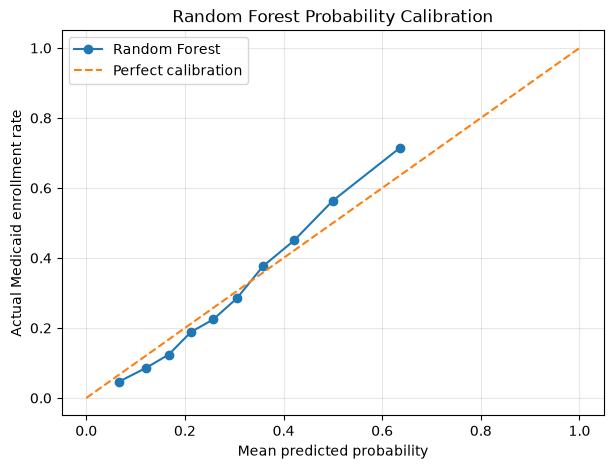

Brier Score: 0.1701


In [133]:

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

# Calculate calibration curve on validation data
fraction_positive, mean_predicted = calibration_curve(
    y_val,
    income_val_prob,
    n_bins=10,
    strategy="quantile"
)

# Plot calibration
plt.figure(figsize=(7, 5))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Actual Medicaid enrollment rate")
plt.title("Random Forest Probability Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Brier score
print(
    "Brier Score:",
    round(
        brier_score_loss(y_val, income_val_prob),
        4
    )
)


### Gradient Boosting (XGBoost)

In [135]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss

# Step 1: Create dense preprocessing
preprocessor_gb = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features_income
        )
    ],
    sparse_threshold=0
)

# Step 2: Create Gradient Boosting pipeline
gb_model = Pipeline([
    ("preprocessor", preprocessor_gb),
    ("model", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ))
])

# Step 3: Train model
gb_model.fit(X_train_income, y_train)

# Step 4: Predict validation probabilities
gb_val_prob = gb_model.predict_proba(
    X_val_income
)[:, 1]

# Step 5: Evaluate
gb_auc = roc_auc_score(y_val, gb_val_prob)

gb_brier = brier_score_loss(
    y_val,
    gb_val_prob
)

print("GRADIENT BOOSTING RESULTS")
print("Validation ROC-AUC:", round(gb_auc, 4))
print("Brier Score:", round(gb_brier, 4))

print("\nRANDOM FOREST RESULTS")
print("Validation ROC-AUC:", 0.7771)
print("Brier Score:", 0.1701)


GRADIENT BOOSTING RESULTS
Validation ROC-AUC: 0.7905
Brier Score: 0.1641

RANDOM FOREST RESULTS
Validation ROC-AUC: 0.7771
Brier Score: 0.1701


### Tuning number of boosting interactions

In [136]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
import pandas as pd

# Preprocess using training data only
X_train_gb = preprocessor_gb.transform(X_train_income)
X_val_gb = preprocessor_gb.transform(X_val_income)

iterations = [100, 200, 300, 500]

gb_results = []

for n_iter in iterations:

    model = HistGradientBoostingClassifier(
        max_iter=n_iter,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )

    model.fit(X_train_gb, y_train)

    val_prob = model.predict_proba(X_val_gb)[:, 1]

    gb_results.append({
        "max_iter": n_iter,
        "val_auc": roc_auc_score(y_val, val_prob),
        "brier_score": brier_score_loss(y_val, val_prob)
    })

gb_results_df = pd.DataFrame(gb_results)

print(gb_results_df.round(4))


   max_iter  val_auc  brier_score
0       100   0.7806       0.1685
1       200   0.7905       0.1641
2       300   0.7916       0.1635
3       500   0.7922       0.1632


### Vary the complexity of the individual trees within Gradient Boosting.

In [137]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
import pandas as pd

leaf_nodes = [15, 31, 63]

gb_leaf_results = []

for nodes in leaf_nodes:

    model = HistGradientBoostingClassifier(
        max_iter=500,
        learning_rate=0.05,
        max_leaf_nodes=nodes,
        l2_regularization=1.0,
        random_state=42
    )

    model.fit(X_train_gb, y_train)

    val_prob = model.predict_proba(X_val_gb)[:, 1]

    gb_leaf_results.append({
        "max_leaf_nodes": nodes,
        "iterations_used": model.n_iter_,
        "val_auc": roc_auc_score(y_val, val_prob),
        "brier_score": brier_score_loss(y_val, val_prob)
    })

gb_leaf_df = pd.DataFrame(gb_leaf_results)

print(gb_leaf_df.round(4))


   max_leaf_nodes  iterations_used  val_auc  brier_score
0              15              500   0.7896       0.1642
1              31              500   0.7922       0.1632
2              63              500   0.7937       0.1626


### Threshold analysis for Gradient Boosting

In [138]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss

# Train our best Gradient Boosting configuration
gb_best = HistGradientBoostingClassifier(
    max_iter=500,
    learning_rate=0.05,
    max_leaf_nodes=63,
    l2_regularization=1.0,
    random_state=42
)

gb_best.fit(X_train_gb, y_train)

# Validation probabilities
gb_best_prob = gb_best.predict_proba(X_val_gb)[:, 1]

# Evaluate thresholds
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

results = []

y_true = np.asarray(y_val, dtype=int)

for threshold in thresholds:

    y_pred = (gb_best_prob >= threshold).astype(int)

    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    precision = TP / (TP + FP) if (TP + FP) else 0
    recall = TP / (TP + FN) if (TP + FN) else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    specificity = TN / (TN + FP) if (TN + FP) else 0
    balanced_accuracy = (recall + specificity) / 2

    results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "balanced_accuracy": balanced_accuracy
    })

gb_threshold_df = pd.DataFrame(results)

print(gb_threshold_df.round(4))

print("\nValidation ROC-AUC:",
      round(roc_auc_score(y_val, gb_best_prob), 4))

print("Brier Score:",
      round(brier_score_loss(y_val, gb_best_prob), 4))


   threshold  precision  recall      f1  balanced_accuracy
0       0.20     0.4523  0.8600  0.5929             0.7005
1       0.25     0.4890  0.7992  0.6068             0.7155
2       0.30     0.5235  0.7329  0.6107             0.7194
3       0.35     0.5573  0.6650  0.6064             0.7160
4       0.40     0.5943  0.5987  0.5965             0.7093
5       0.45     0.6255  0.5264  0.5717             0.6938
6       0.50     0.6553  0.4502  0.5337             0.6729

Validation ROC-AUC: 0.7937
Brier Score: 0.1626


#### Gradient Boosting achieves better precision, F1-score, and balanced accuracy except recall. Therefore,Gradient Boosting as our provisional final model, with a classification threshold of 0.30.

##### Examine Gradient Boosting calibration

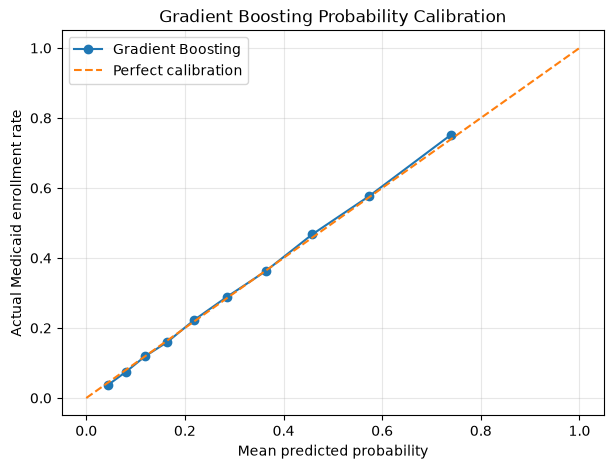

Gradient Boosting Brier Score: 0.1626


In [139]:

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt

# Calibration curve for Gradient Boosting
fraction_positive, mean_predicted = calibration_curve(
    y_val,
    gb_best_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Gradient Boosting"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Actual Medicaid enrollment rate")
plt.title("Gradient Boosting Probability Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(
    "Gradient Boosting Brier Score:",
    round(brier_score_loss(y_val, gb_best_prob), 4)
)


#### Final Audit

In [140]:

print("CATEGORICAL FEATURES")
for feature in categorical_features:
    print("-", feature)

print("\nNUMERICAL FEATURES")
for feature in numerical_features_income:
    print("-", feature)

print("\nTOTAL FEATURES:",
      len(categorical_features) + len(numerical_features_income))


CATEGORICAL FEATURES
- race_group
- education_group
- marital_group
- employment_group
- citizenship_group
- sex_group
- health_group
- statefip

NUMERICAL FEATURES
- age
- famsize
- nchild
- fpl_ratio
- year
- ftotval
- inctot

TOTAL FEATURES: 15


In [141]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss

# Remove FPL ratio from predictors
features_no_fpl = [
    feature for feature in X_train_income.columns
    if feature != "fpl_ratio"
]

# Keep all other predictors
X_train_no_fpl = X_train_income[features_no_fpl].copy()
X_val_no_fpl = X_val_income[features_no_fpl].copy()

# Update numerical feature list
numerical_no_fpl = [
    feature for feature in numerical_features_income
    if feature != "fpl_ratio"
]

# Rebuild preprocessing with the new feature list
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor_no_fpl = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_no_fpl
        )
    ],
    sparse_threshold=0
)

# Train the same Gradient Boosting configuration
gb_no_fpl = Pipeline([
    ("preprocessor", preprocessor_no_fpl),
    ("model", HistGradientBoostingClassifier(
        max_iter=500,
        learning_rate=0.05,
        max_leaf_nodes=63,
        l2_regularization=1.0,
        random_state=42
    ))
])

gb_no_fpl.fit(X_train_no_fpl, y_train)

# Validation predictions
gb_no_fpl_prob = gb_no_fpl.predict_proba(
    X_val_no_fpl
)[:, 1]

# Compare models
print("WITH FPL RATIO")
print("ROC-AUC:", 0.7937)
print("Brier Score:", 0.1626)

print("\nWITHOUT FPL RATIO")
print(
    "ROC-AUC:",
    round(roc_auc_score(y_val, gb_no_fpl_prob), 4)
)
print(
    "Brier Score:",
    round(brier_score_loss(y_val, gb_no_fpl_prob), 4)
)


WITH FPL RATIO
ROC-AUC: 0.7937
Brier Score: 0.1626

WITHOUT FPL RATIO
ROC-AUC: 0.7932
Brier Score: 0.1628


In [143]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score
)

# 1. Use our selected 15 predictors
final_features = categorical_features + numerical_features_income

# 2. Combine training and validation observations
df_train_final = pd.concat(
    [df_train, df_val],
    axis=0
)

# 3. Create feature matrices and target vectors
X_train_final = df_train_final[final_features].copy()
y_train_final = df_train_final["medicaid"].copy()

X_test_final = df_test[final_features].copy()
y_test_final = df_test["medicaid"].copy()

print("Training observations:", len(X_train_final))
print("Testing observations:", len(X_test_final))

# 4. Create dense preprocessing
final_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features_income
        )
    ],
    sparse_threshold=0
)

# 5. Build final Gradient Boosting pipeline
final_model = Pipeline([
    ("preprocessor", final_preprocessor),
    ("model", HistGradientBoostingClassifier(
        max_iter=500,
        learning_rate=0.05,
        max_leaf_nodes=63,
        l2_regularization=1.0,
        random_state=42
    ))
])

# 6. Fit model on training + validation data
final_model.fit(X_train_final, y_train_final)

# 7. Predict test probabilities
test_prob = final_model.predict_proba(
    X_test_final
)[:, 1]

# 8. Apply selected threshold
test_pred = (test_prob >= 0.30).astype(int)

# 9. Evaluate final test performance
print("\nFINAL TEST PERFORMANCE")

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test_final, test_prob), 4)
)

print(
    "Brier Score:",
    round(brier_score_loss(y_test_final, test_prob), 4)
)

print(
    "Accuracy:",
    round(accuracy_score(y_test_final, test_pred), 4)
)

print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(y_test_final, test_pred), 4)
)

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test_final,
        test_pred,
        target_names=["Not Enrolled", "Enrolled"],
        digits=4
    )
)

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test_final, test_pred))


Training observations: 218226
Testing observations: 38496

FINAL TEST PERFORMANCE
ROC-AUC: 0.7968
Brier Score: 0.1611
Accuracy: 0.7192
Balanced Accuracy: 0.7238

CLASSIFICATION REPORT
              precision    recall  f1-score   support

Not Enrolled     0.8602    0.7121    0.7792     26782
    Enrolled     0.5277    0.7354    0.6145     11714

    accuracy                         0.7192     38496
   macro avg     0.6940    0.7238    0.6968     38496
weighted avg     0.7590    0.7192    0.7291     38496


CONFUSION MATRIX
[[19072  7710]
 [ 3099  8615]]


In [144]:

import joblib
from pathlib import Path

# Create folder for saved models
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Save complete trained pipeline
model_path = model_dir / "medicaid_gradient_boosting.joblib"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Location:", model_path.resolve())

# Save classification threshold separately
threshold_path = model_dir / "classification_threshold.joblib"

joblib.dump(0.30, threshold_path)

print("Threshold saved successfully!")
print("Location:", threshold_path.resolve())


Model saved successfully!
Location: C:\Users\chukw\OneDrive\Desktop\Medicaid_SNAP_Project\models\medicaid_gradient_boosting.joblib
Threshold saved successfully!
Location: C:\Users\chukw\OneDrive\Desktop\Medicaid_SNAP_Project\models\classification_threshold.joblib
